# Indian Financial Time-Series Analysis: Forecasting, Volatility and Anomaly Detection

**Course project pipeline** covering visualization, stationarity, ACF/PACF, ARIMA, STL decomposition, exponential smoothing, VAR, GARCH, RNN/LSTM/GRU, and anomaly detection.

## Research question
Can historical NIFTY 50 prices and related Indian market indices support useful one-step-ahead price forecasts and conditional-volatility estimates, and what patterns emerge in market returns?

## Data source and reproducibility
This notebook fetches a small set of public Parquet files from the community-maintained [Indian Market Historical Data repository](https://github.com/aswinv90/indian-market-historical-data). Its README documents daily index data for NIFTY 50, NIFTY BANK, NIFTY IT, NIFTY PHARMA and INDIA VIX, with coverage beginning in 2007–2011 depending on the index. Data is updated on trading days. We will check actual dates, missing values and data quality after loading.

The analysis uses the common date intersection of the selected series, from 2010 onward where available. Since the indices do not all start on the same date, the panel's actual start date may be later than 2010.

**Important:** This is not an investment strategy. Stock-index returns are noisy, and low forecast error on price levels can be misleading. Every forecasting model is evaluated on the same final holdout period and against a naïve “tomorrow equals today” baseline. The test set is not used for model selection or scaling.

## 0. Environment setup

Run once in the notebook environment. PyTorch is used for the vanilla RNN, LSTM and GRU models; these models can run on CPU, though training may take a few minutes.

```bash
python -m pip install pandas numpy matplotlib seaborn requests pyarrow statsmodels scikit-learn arch torch jupyter
```

In [15]:
import io
import time
import warnings
from copy import deepcopy
from itertools import product

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.api import VAR
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
sns.set_theme(style="whitegrid")

try:
    from arch import arch_model
    ARCH_AVAILABLE = True
except ImportError:
    ARCH_AVAILABLE = False
    print("Package 'arch' is not installed. Run: pip install arch")

try:
    import torch
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset
    torch.manual_seed(RANDOM_SEED)
    TORCH_AVAILABLE = True
except ImportError:
    TORCH_AVAILABLE = False
    print("PyTorch is not installed. Run: pip install torch")

print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("PyTorch available:", TORCH_AVAILABLE)
print("arch available:", ARCH_AVAILABLE)

pandas: 2.3.3
NumPy: 2.3.4
PyTorch available: True
arch available: True


## 1. Download and inspect the data

The files are loaded directly from the repository's `data/INDICES/` directory. The helper handles dates stored either as a column or as the DataFrame index. If the source's file layout changes, the loading cell will fail explicitly rather than silently producing an empty dataset.

In [16]:
BASE_URL = "https://raw.githubusercontent.com/aswinv90/indian-market-historical-data/main/data/INDICES/"
INDEX_FILES = {
    "NIFTY50": "NIFTY_50.parquet",
    "BANK": "NIFTY_BANK.parquet",
    "IT": "NIFTY_IT.parquet",
    "PHARMA": "NIFTY_PHARMA.parquet",
    "VIX": "INDIA_VIX.parquet",
}
START_DATE = "2010-01-01"


def load_index_file(asset_name: str, filename: str) -> pd.DataFrame:
    url = BASE_URL + filename
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    df = pd.read_parquet(io.BytesIO(response.content))
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]

    # Identify and parse the date index robustly.
    date_col = next((c for c in df.columns if c.lower().strip() in {"date", "datetime", "timestamp"}), None)
    if date_col is not None:
        dates = pd.to_datetime(df[date_col], errors="coerce")
        df = df.drop(columns=[date_col])
        df.index = pd.DatetimeIndex(dates, name="Date")
    elif isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index, errors="coerce")
        df.index.name = "Date"
    else:
        df = df.reset_index()
        candidate = next((c for c in df.columns if str(c).lower().strip() in {"index", "date", "datetime", "timestamp"}), None)
        if candidate is None:
            raise ValueError(f"Could not identify date column in {filename}. Columns: {df.columns.tolist()}")
        dates = pd.to_datetime(df[candidate], errors="coerce")
        df = df.drop(columns=[candidate])
        df.index = pd.DatetimeIndex(dates, name="Date")

    df = df.loc[~df.index.isna()].sort_index()
    df = df[~df.index.duplicated(keep="last")]
    # Normalize common spelling/case differences without changing values.
    normalized = {str(c).lower().replace("_", " ").strip(): c for c in df.columns}
    close_col = normalized.get("close")
    if close_col is None:
        raise ValueError(f"No Close column in {filename}. Columns: {df.columns.tolist()}")
    df = df.rename(columns={close_col: "Close"})
    return df


market = {}
for asset, filename in INDEX_FILES.items():
    print(f"Downloading {asset} ...")
    market[asset] = load_index_file(asset, filename)

close_all = pd.concat({asset: df["Close"].rename(asset) for asset, df in market.items()}, axis=1).sort_index()
close_all = close_all.loc[START_DATE:]
close = close_all.dropna(how="any")

print("\nIndividual series coverage:")
coverage = pd.DataFrame({
    "first_date": {k: v.index.min().date() for k, v in market.items()},
    "last_date": {k: v.index.max().date() for k, v in market.items()},
    "rows": {k: len(v) for k, v in market.items()},
})
display(coverage)

print(f"\nCommon aligned panel: {close.index.min().date()} to {close.index.max().date()} | {len(close):,} trading observations")
display(close.head())
display(close.tail())


Individual series coverage:


,first_date,last_date,rows
NIFTY50,2007-09-17,2026-10-23,4686
BANK,2007-09-17,2026-10-23,4701
IT,2007-09-17,2026-10-23,4701
PHARMA,2011-01-31,2026-10-23,3873
VIX,2008-03-03,2026-10-23,4567



Common aligned panel: 2011-01-31 to 2026-10-23 | 3,842 trading observations


,NIFTY50,BANK,IT,PHARMA,VIX
Date,,,,,
2011-01-31,5505.899902,10641.849609,6971.250000,4689.799805,23.410000
2011-02-01,5417.200195,10481.200195,6898.649902,4629.250000,23.730000
2011-02-02,5432.000000,10470.150391,6961.649902,4630.200195,23.520000
2011-02-03,5526.750000,10670.599609,6998.899902,4640.899902,22.690001
2011-02-04,5395.750000,10433.849609,6850.649902,4573.250000,24.410000


,NIFTY50,BANK,IT,PHARMA,VIX
Date,,,,,
2026-10-16,23146.150391,55844.000000,31924.099609,25781.650391,14.060000
2026-10-19,22888.949219,55488.101562,31516.300781,25615.000000,14.770000
2026-10-21,22811.349609,54976.898438,32422.500000,25565.900391,15.680000
2026-10-22,22687.650391,54925.699219,32081.250000,25596.650391,15.760000
2026-10-23,22600.000000,54287.351562,31995.500000,25329.449219,16.860001


### Data-quality checks and feature construction

For indices, we use the `Close` values; for model inputs we derive log returns. Log returns are useful for comparing changes across indices and for volatility modeling. We do **not** interpolate missing trading days: the multivariate analysis uses observed dates shared across the selected series.

In [17]:
assert not close.empty, "No common data found. Check the repository URLs and network connection."
assert close.index.is_monotonic_increasing
assert close.index.is_unique
assert (close > 0).all().all(), "Non-positive index values prevent log returns."

log_close = np.log(close)
returns = log_close.diff().dropna()

quality = pd.DataFrame({
    "missing": close.isna().sum(),
    "nonpositive": (close <= 0).sum(),
    "unique_dates": close.nunique(),
})
display(quality)
print("Return summary:")
display(returns.describe().T)

,missing,nonpositive,unique_dates
NIFTY50,0,0,3811
BANK,0,0,3832
IT,0,0,3823
PHARMA,0,0,3814
VIX,0,0,1536


Return summary:


,count,mean,std,min,25%,50%,75%,max
NIFTY50,3841.0,0.000368,0.010414,-0.139038,-0.004755,0.000502,0.005989,0.084003
BANK,3841.0,0.000424,0.014353,-0.183130,-0.006407,0.000573,0.007282,0.099951
IT,3841.0,0.000397,0.013686,-0.124903,-0.006479,0.000365,0.007420,0.089220
PHARMA,3841.0,0.000439,0.011524,-0.093507,-0.005618,0.000500,0.006924,0.098650
VIX,3841.0,-0.000085,0.052918,-0.414618,-0.027386,-0.002997,0.024391,0.504556


## 2. Time-series visualization: line plots, rolling means and calendar heatmap

The close-level chart shows long-run market movement; rolling means smooth short-term noise. The calendar heatmap uses monthly NIFTY 50 returns, which is more interpretable than heatmapping raw prices.

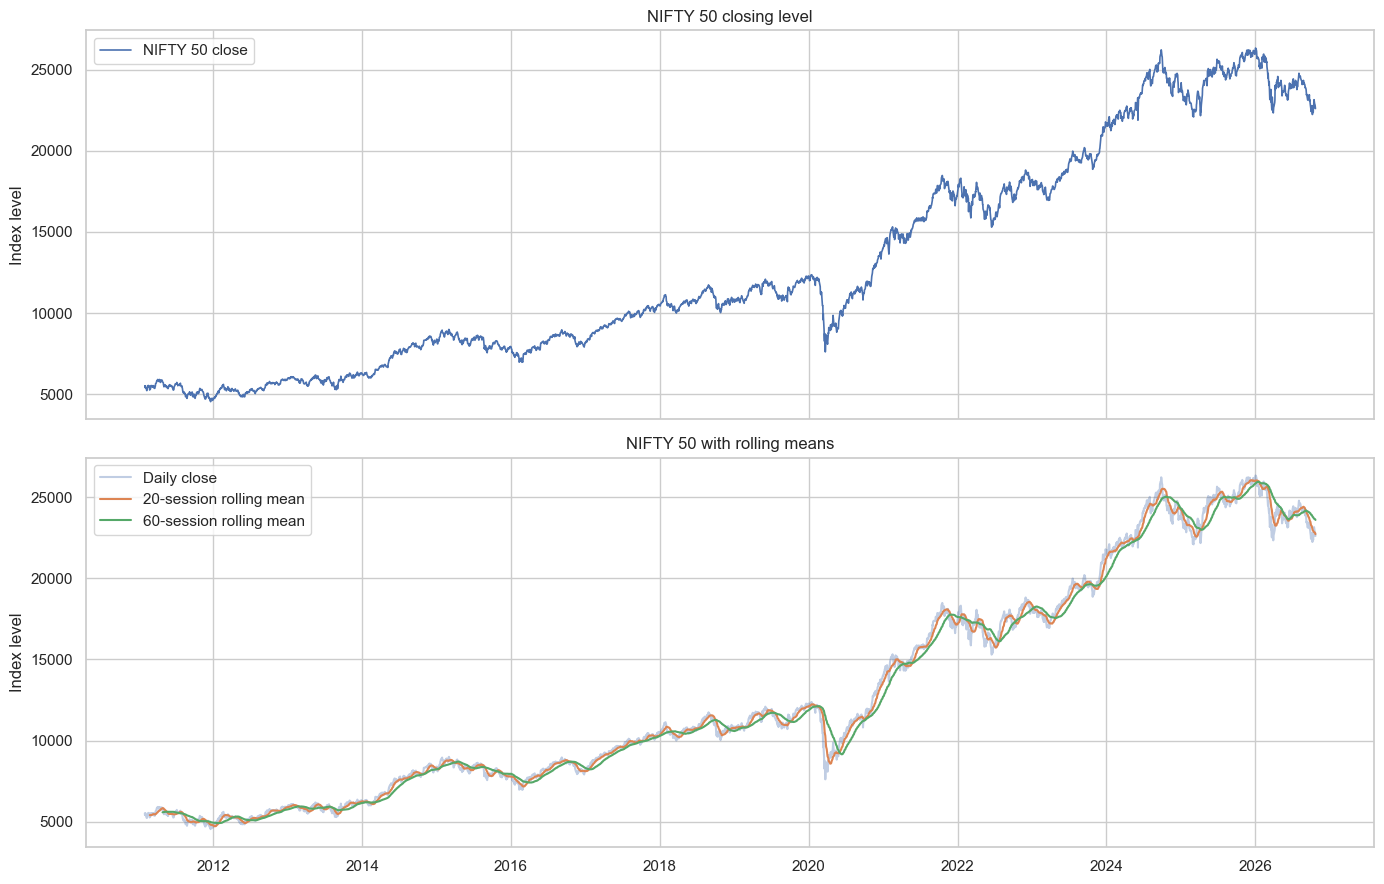

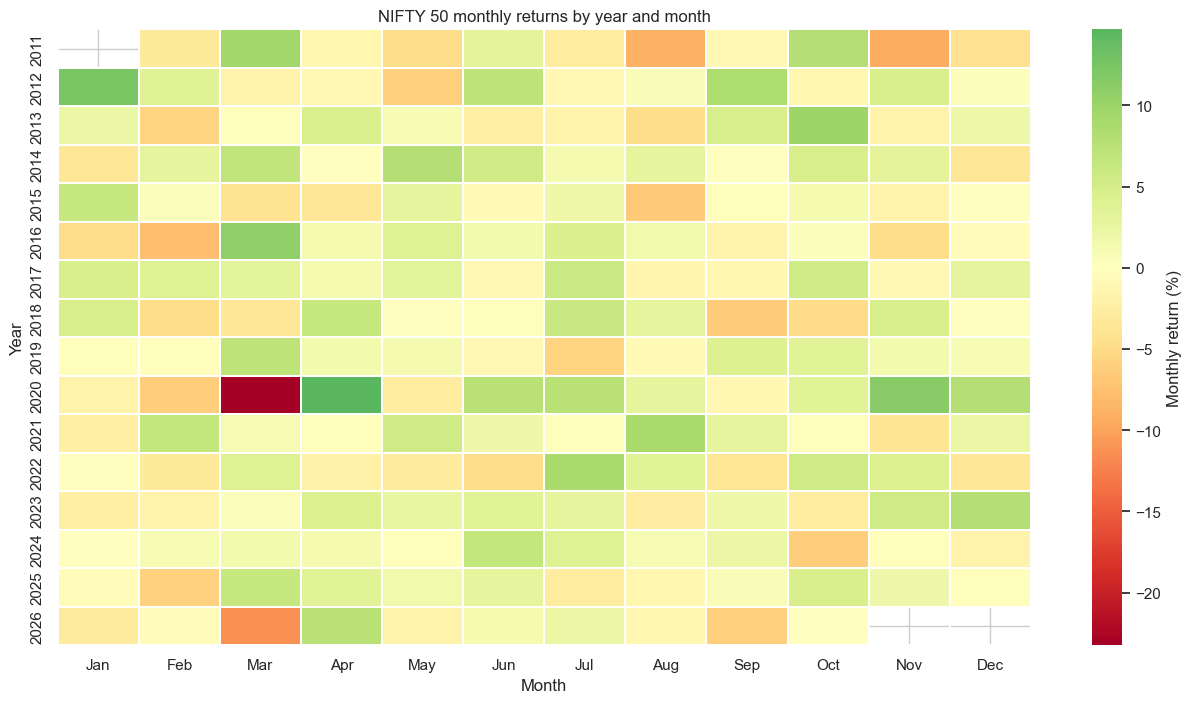

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
axes[0].plot(close.index, close["NIFTY50"], label="NIFTY 50 close", linewidth=1.2)
axes[0].set_title("NIFTY 50 closing level")
axes[0].set_ylabel("Index level")
axes[0].legend()

axes[1].plot(close.index, close["NIFTY50"], alpha=0.35, label="Daily close")
axes[1].plot(close.index, close["NIFTY50"].rolling(20).mean(), label="20-session rolling mean")
axes[1].plot(close.index, close["NIFTY50"].rolling(60).mean(), label="60-session rolling mean")
axes[1].set_title("NIFTY 50 with rolling means")
axes[1].set_ylabel("Index level")
axes[1].legend()
plt.tight_layout()
plt.show()

monthly_close = close["NIFTY50"].resample("ME").last()
monthly_returns = monthly_close.pct_change().dropna()
monthly_table = monthly_returns.to_frame("return")
monthly_table["Year"] = monthly_table.index.year
monthly_table["Month"] = monthly_table.index.month
heatmap_data = monthly_table.pivot(index="Year", columns="Month", values="return")
heatmap_data = heatmap_data.reindex(columns=range(1, 13))

plt.figure(figsize=(13, max(4, len(heatmap_data) * 0.45)))
sns.heatmap(heatmap_data * 100, cmap="RdYlGn", center=0, annot=False,
            cbar_kws={"label": "Monthly return (%)"}, linewidths=0.2)
plt.title("NIFTY 50 monthly returns by year and month")
plt.xlabel("Month")
plt.ylabel("Year")
plt.xticks(np.arange(12) + 0.5, ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.tight_layout()
plt.show()

## 3. Stationarity and differencing

We test the log price level and log returns using both the Augmented Dickey–Fuller (ADF) test and KPSS. Their null hypotheses differ: ADF's null is a unit root; KPSS's null is stationarity. Reading them together is more informative than relying on one test alone.

In [19]:
def stationarity_tests(series: pd.Series, name: str) -> dict:
    x = series.dropna().astype(float)
    adf_stat, adf_p, adf_lags, adf_n, *_ = adfuller(x, autolag="AIC")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_stat, kpss_p, kpss_lags, *_ = kpss(x, regression="c", nlags="auto")
    return {
        "series": name,
        "ADF statistic": adf_stat,
        "ADF p-value": adf_p,
        "ADF lags": adf_lags,
        "KPSS statistic": kpss_stat,
        "KPSS p-value": kpss_p,
        "KPSS lags": kpss_lags,
    }

stationarity = pd.DataFrame([
    stationarity_tests(log_close["NIFTY50"], "log(NIFTY 50 close)"),
    stationarity_tests(returns["NIFTY50"], "NIFTY 50 log returns"),
])
display(stationarity)

,series,ADF statistic,ADF p-value,ADF lags,KPSS statistic,KPSS p-value,KPSS lags
0,log(NIFTY 50 close),-0.723086,8.406789e-01,12,9.431000,0.01,39
1,NIFTY 50 log returns,-14.824732,1.939456e-27,16,0.043883,0.10,5


## 4. Autocorrelation and partial autocorrelation

ACF/PACF plots on returns help assess short-lag linear dependence. Applying ACF to squared returns is also useful: persistent autocorrelation in squared returns is a common sign of volatility clustering and motivates a GARCH-family model.

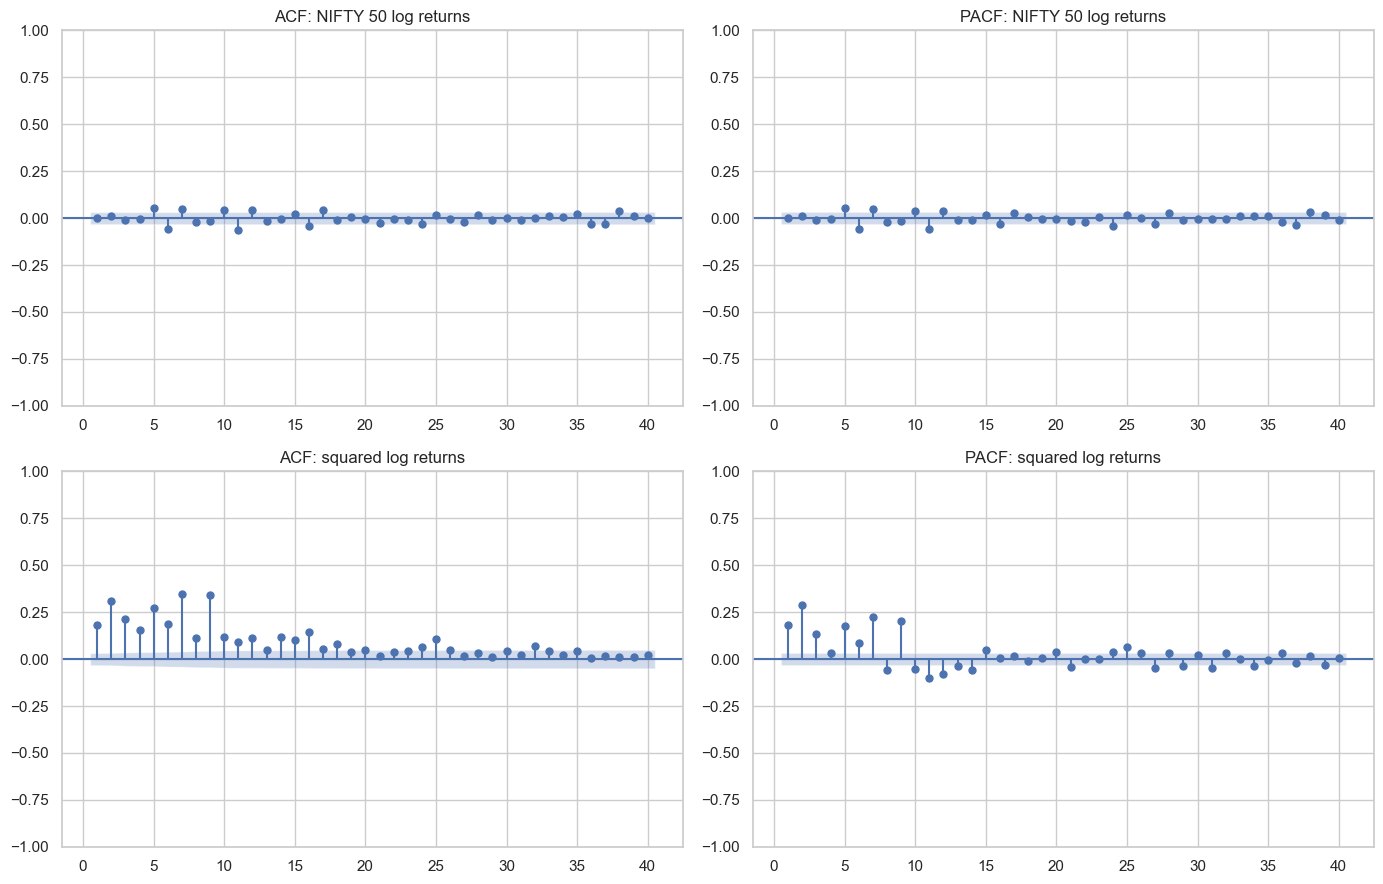

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_acf(returns["NIFTY50"], lags=40, ax=axes[0, 0], zero=False)
axes[0, 0].set_title("ACF: NIFTY 50 log returns")
plot_pacf(returns["NIFTY50"], lags=40, method="ywm", ax=axes[0, 1], zero=False)
axes[0, 1].set_title("PACF: NIFTY 50 log returns")
plot_acf(returns["NIFTY50"] ** 2, lags=40, ax=axes[1, 0], zero=False)
axes[1, 0].set_title("ACF: squared log returns")
plot_pacf(returns["NIFTY50"] ** 2, lags=40, method="ywm", ax=axes[1, 1], zero=False)
axes[1, 1].set_title("PACF: squared log returns")
plt.tight_layout()
plt.show()

## 5. STL seasonal decomposition

Financial markets do not necessarily have strong, stable seasonality. Here STL is applied to **absolute daily log returns** using a period of five trading observations (approximately one trading week). Treat the seasonal component as exploratory; do not claim seasonality unless the estimated pattern is stable and meaningful.

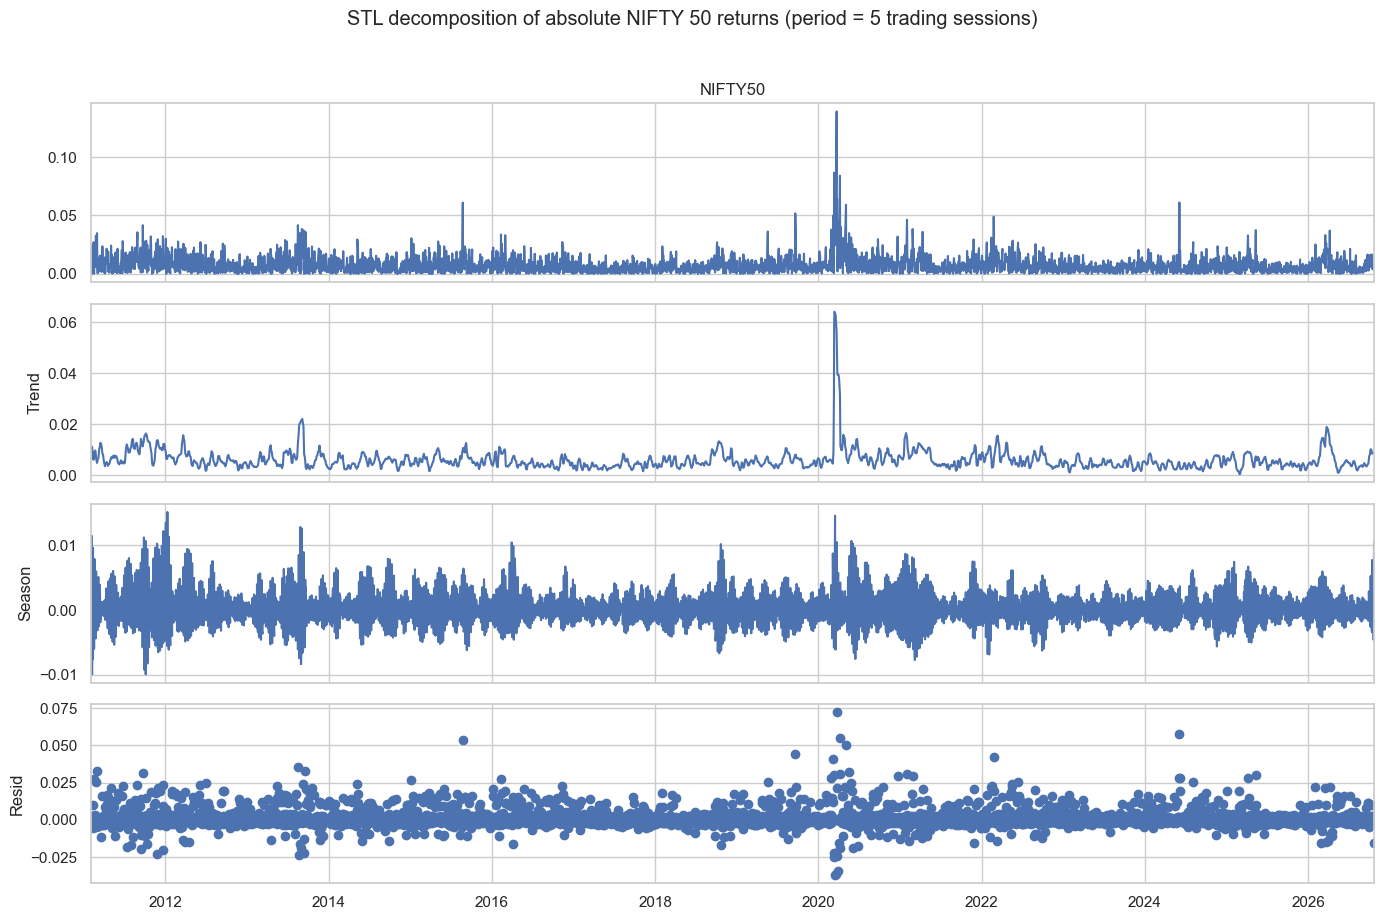

In [21]:
abs_returns = returns["NIFTY50"].abs()
stl_fit = STL(abs_returns, period=5, robust=True).fit()
fig = stl_fit.plot()
fig.set_size_inches(14, 9)
fig.suptitle("STL decomposition of absolute NIFTY 50 returns (period = 5 trading sessions)", y=1.02)
plt.tight_layout()
plt.show()

## 6. Forecasting setup and chronological holdout

The target for the main forecasting comparison is the **NIFTY 50 closing level** represented as log close for numerical stability. All model forecasts are converted back to index levels before computing error metrics. The final 252 shared observations (roughly one trading year) are held out. No random train/test split is used.

In [22]:
TEST_SIZE = min(252, max(60, int(len(log_close) * 0.2)))
if len(log_close) <= TEST_SIZE + 100:
    raise ValueError("Not enough observations for the chosen holdout; inspect data coverage.")

nifty_log = log_close["NIFTY50"].astype(float)
split_idx = len(nifty_log) - TEST_SIZE
train_log = nifty_log.iloc[:split_idx]
test_log = nifty_log.iloc[split_idx:]
train_dates = train_log.index
test_dates = test_log.index

print(f"Training: {train_dates.min().date()} through {train_dates.max().date()} ({len(train_log):,} observations)")
print(f"Testing : {test_dates.min().date()} through {test_dates.max().date()} ({len(test_log):,} observations)")

# One-step naïve/random-walk benchmark: tomorrow's close equals today's observed close.
previous_log = np.r_[train_log.iloc[-1], test_log.values[:-1]]
predictions_log = {"Naive (last close)": previous_log.copy()}

Training: 2011-01-31 through 2025-10-13 (3,590 observations)
Testing : 2025-10-14 through 2026-10-23 (252 observations)


## 7. ARIMA model selection and walk-forward evaluation

We select a small ARIMA(p, 1, q) grid by AIC using **training data only**. The differencing order is fixed at 1 because price levels are typically non-stationary while log returns are the stationary modeling target; stationarity tests above should be used to verify this for the actual sample. After each one-step forecast, the observed test value is appended to update the model's state without re-estimating parameters.

In [23]:
results_aic = []
for p, q in product(range(3), range(3)):
    order = (p, 1, q)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fitted = ARIMA(train_log.to_numpy(), order=order).fit()
        results_aic.append((fitted.aic, order))
    except Exception as exc:
        print(f"Skipped ARIMA{order}: {exc}")

if not results_aic:
    raise RuntimeError("No ARIMA candidate fitted successfully.")
best_aic, best_order = min(results_aic, key=lambda x: x[0])
print("AIC-ranked candidates:", sorted(results_aic)[:5])
print(f"Selected ARIMA{best_order} with training AIC={best_aic:.2f}")

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    arima_result = ARIMA(train_log.to_numpy(), order=best_order).fit()

arima_log_preds = []
for actual in test_log.to_numpy():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        forecast = float(np.asarray(arima_result.forecast(steps=1)).reshape(-1)[0])
        arima_log_preds.append(forecast)
        arima_result = arima_result.append([float(actual)], refit=False)

predictions_log[f"ARIMA{best_order}"] = np.asarray(arima_log_preds)

AIC-ranked candidates: [(np.float64(-22495.031988834122), (0, 1, 0)), (np.float64(-22493.175678589618), (1, 1, 0)), (np.float64(-22493.171769906774), (0, 1, 1)), (np.float64(-22491.556126395517), (2, 1, 0)), (np.float64(-22491.555528341967), (0, 1, 2))]
Selected ARIMA(0, 1, 0) with training AIC=-22495.03


## 8. Exponential smoothing (Holt's linear trend)

Holt's method is fitted on the training log-close series. During the holdout period, the model's level and trend states are updated with each newly observed close while its smoothing parameters remain fixed. This gives one-step-ahead forecasts using only information that would have been available at each date.

In [24]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    holt_fit = ExponentialSmoothing(
        train_log.to_numpy(), trend="add", initialization_method="estimated"
    ).fit(optimized=True)

alpha = float(holt_fit.params["smoothing_level"])
beta = float(holt_fit.params["smoothing_trend"])
level = float(np.asarray(holt_fit.level)[-1])
trend = float(np.asarray(holt_fit.trend)[-1])
holt_log_preds = []
for actual in test_log.to_numpy():
    forecast = level + trend
    holt_log_preds.append(forecast)
    new_level = alpha * actual + (1 - alpha) * (level + trend)
    new_trend = beta * (new_level - level) + (1 - beta) * trend
    level, trend = new_level, new_trend

predictions_log["Holt exponential smoothing"] = np.asarray(holt_log_preds)
print(f"Estimated smoothing parameters: alpha={alpha:.4f}, beta={beta:.4f}")

Estimated smoothing parameters: alpha=1.0000, beta=0.0000


## 9. RNN, LSTM and GRU forecasting

Each neural model uses the previous 30 observed log-close values to predict the next value. The scaler is fitted only on the training period. Validation samples are taken from the end of the training period, and the final holdout remains unseen during training. At test time, forecasts are one-step-ahead, so previously observed holdout values may enter later input windows (a standard walk-forward setup).

In [25]:
if not TORCH_AVAILABLE:
    raise ImportError("Install PyTorch with `pip install torch` to run the RNN/LSTM/GRU section.")

WINDOW = 30
scaler = MinMaxScaler()
scaler.fit(train_log.to_numpy().reshape(-1, 1))
scaled_all = scaler.transform(nifty_log.to_numpy().reshape(-1, 1)).astype(np.float32).ravel()

X_train_list, y_train_list, X_test_list, y_test_list = [], [], [], []
for target_pos in range(WINDOW, len(scaled_all)):
    x = scaled_all[target_pos - WINDOW:target_pos]
    y = scaled_all[target_pos]
    if target_pos < split_idx:
        X_train_list.append(x)
        y_train_list.append(y)
    else:
        X_test_list.append(x)
        y_test_list.append(y)

X_train_all = np.asarray(X_train_list, dtype=np.float32).reshape(-1, WINDOW, 1)
y_train_all = np.asarray(y_train_list, dtype=np.float32).reshape(-1, 1)
X_test_nn = np.asarray(X_test_list, dtype=np.float32).reshape(-1, WINDOW, 1)
y_test_nn = np.asarray(y_test_list, dtype=np.float32).reshape(-1, 1)
assert len(X_test_nn) == len(test_log), "Neural test sequences are not aligned with the holdout."

class SequenceForecaster(nn.Module):
    def __init__(self, kind: str, hidden_size: int = 32):
        super().__init__()
        kind = kind.upper()
        if kind == "RNN":
            self.sequence_layer = nn.RNN(input_size=1, hidden_size=hidden_size, batch_first=True, nonlinearity="tanh")
        elif kind == "LSTM":
            self.sequence_layer = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True)
        elif kind == "GRU":
            self.sequence_layer = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        else:
            raise ValueError("kind must be RNN, LSTM, or GRU")
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequence_output, _ = self.sequence_layer(x)
        return self.head(sequence_output[:, -1, :])


def train_sequence_model(kind: str, epochs: int = 35, batch_size: int = 64, patience: int = 6):
    # Use the final 10% of training sequences for early-stopping validation.
    cut = max(1, int(len(X_train_all) * 0.9))
    X_tr = torch.tensor(X_train_all[:cut], dtype=torch.float32)
    y_tr = torch.tensor(y_train_all[:cut], dtype=torch.float32)
    X_val = torch.tensor(X_train_all[cut:], dtype=torch.float32)
    y_val = torch.tensor(y_train_all[cut:], dtype=torch.float32)
    X_te = torch.tensor(X_test_nn, dtype=torch.float32)

    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    model = SequenceForecaster(kind=kind)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.MSELoss()
    best_loss = float("inf")
    best_state = None
    wait = 0
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(epochs):
        model.train()
        losses = []
        for xb, yb in loader:
            optimizer.zero_grad()
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()
            optimizer.step()
            losses.append(float(loss.item()))

        model.eval()
        with torch.no_grad():
            if len(X_val):
                val_loss = float(loss_fn(model(X_val), y_val).item())
            else:
                val_loss = float(np.mean(losses))
        history["train_loss"].append(float(np.mean(losses)))
        history["val_loss"].append(val_loss)

        if val_loss < best_loss - 1e-6:
            best_loss = val_loss
            best_state = deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
        if wait >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred_scaled = model(X_te).cpu().numpy()
    pred_log = scaler.inverse_transform(pred_scaled).ravel()
    return pred_log, history, model

nn_histories = {}
nn_models = {}
for kind in ["RNN", "LSTM", "GRU"]:
    print(f"Training {kind} ...")
    pred_log, hist, trained_model = train_sequence_model(kind)
    predictions_log[kind] = pred_log
    nn_histories[kind] = hist
    nn_models[kind] = trained_model
    print(f"  stopped after {len(hist['train_loss'])} epochs; best validation loss={min(hist['val_loss']):.6f}")

Training RNN ...
  stopped after 33 epochs; best validation loss=0.000062
Training LSTM ...
  stopped after 9 epochs; best validation loss=0.000593
Training GRU ...
  stopped after 19 epochs; best validation loss=0.000069


### Forecast comparison

All models predict the same final holdout. Metrics include MAE, RMSE, MAPE, and directional accuracy. Directional accuracy checks whether the forecast correctly predicts the sign of the next day's change from the previous observed close; it does not imply profitable trading after costs.

,MAE (index points),RMSE (index points),MAPE (%),Directional accuracy (%)
Model,,,,
Naive (last close),155.76,206.33,0.644,0.00%
"ARIMA(0, 1, 0)",155.76,206.33,0.644,0.00%
Holt exponential smoothing,156.40,207.15,0.647,48.02%
RNN,280.35,343.31,1.137,52.78%
GRU,299.24,362.73,1.207,54.37%
LSTM,946.98,"1,076.33",3.790,53.57%


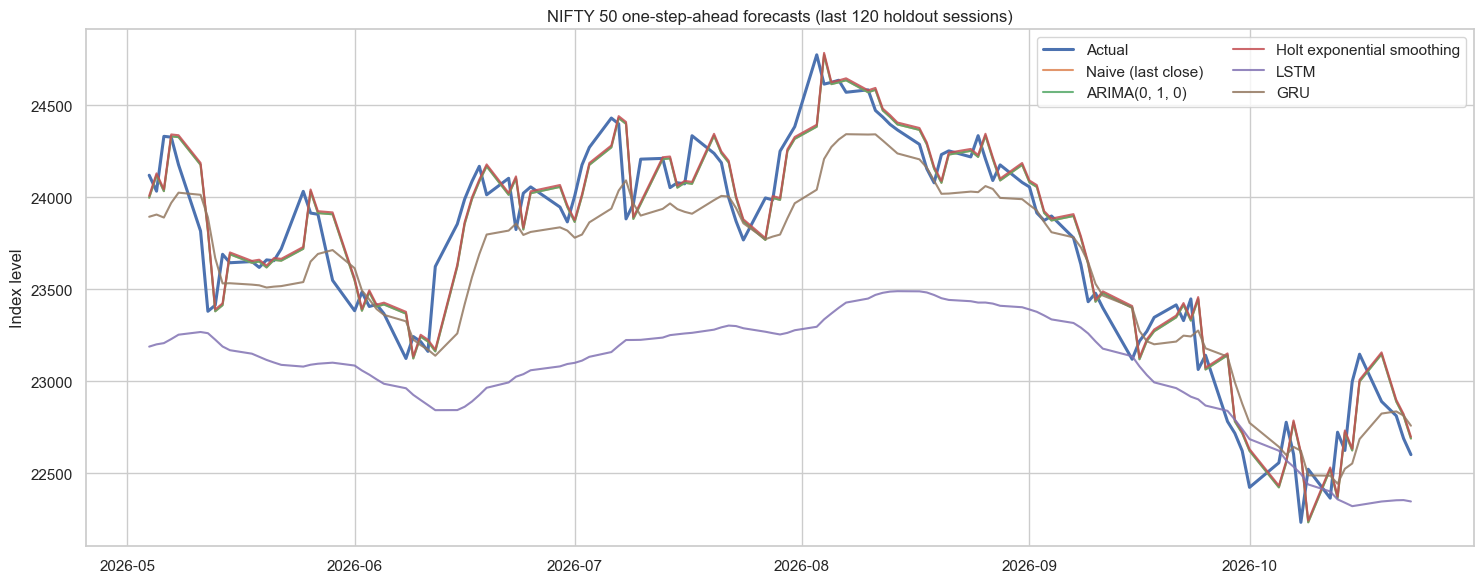

In [26]:
actual_prices = np.exp(test_log.to_numpy())
actual_log = test_log.to_numpy()
previous_actual_log = np.r_[train_log.iloc[-1], actual_log[:-1]]


def forecast_metrics(actual_price, pred_price, actual_log_values, pred_log_values, prev_log_values):
    mae = mean_absolute_error(actual_price, pred_price)
    rmse = np.sqrt(mean_squared_error(actual_price, pred_price))
    mape = np.mean(np.abs((actual_price - pred_price) / actual_price)) * 100
    true_direction = np.sign(actual_log_values - prev_log_values)
    pred_direction = np.sign(pred_log_values - prev_log_values)
    directional_acc = np.mean(true_direction == pred_direction) * 100
    return {"MAE (index points)": mae, "RMSE (index points)": rmse,
            "MAPE (%)": mape, "Directional accuracy (%)": directional_acc}

metric_rows = []
for model_name, pred_log_values in predictions_log.items():
    pred_price_values = np.exp(np.asarray(pred_log_values))
    row = {"Model": model_name}
    row.update(forecast_metrics(actual_prices, pred_price_values, actual_log,
                                np.asarray(pred_log_values), previous_actual_log))
    metric_rows.append(row)

forecast_results = pd.DataFrame(metric_rows).set_index("Model").sort_values("RMSE (index points)")
display(forecast_results.style.format({
    "MAE (index points)": "{:,.2f}",
    "RMSE (index points)": "{:,.2f}",
    "MAPE (%)": "{:.3f}",
    "Directional accuracy (%)": "{:.2f}%",
}))

forecast_prices = pd.DataFrame({name: np.exp(np.asarray(pred)) for name, pred in predictions_log.items()}, index=test_dates)
forecast_prices["Actual"] = actual_prices

# Plot the last 120 holdout days to keep the comparison readable.
plot_frame = forecast_prices.tail(120)
plt.figure(figsize=(15, 6))
plt.plot(plot_frame.index, plot_frame["Actual"], label="Actual", linewidth=2.2)
for model_name in ["Naive (last close)", f"ARIMA{best_order}", "Holt exponential smoothing", "LSTM", "GRU"]:
    if model_name in plot_frame.columns:
        plt.plot(plot_frame.index, plot_frame[model_name], label=model_name, alpha=0.85)
plt.title("NIFTY 50 one-step-ahead forecasts (last 120 holdout sessions)")
plt.ylabel("Index level")
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

## 10. VAR: relationships between market indices

VAR is fit on log returns of NIFTY 50, Bank NIFTY, NIFTY IT, NIFTY Pharma and India VIX. Price levels are not used directly because they are non-stationary. AIC selects the lag order on training data; predictions are one-step-ahead, updating the lag history with each newly observed test value.

/Users/vanshi/miniconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


Selected VAR lag order: 2
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Mon, 26, Oct, 2026
Time:                     23:12:41
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -43.8765
Nobs:                     3587.00    HQIC:                  -43.9375
Log likelihood:           53468.9    FPE:                8.00741e-20
AIC:                     -43.9713    Det(Omega_mle):     7.88576e-20
--------------------------------------------------------------------
Results for equation NIFTY50
                coefficient       std. error           t-stat            prob
-----------------------------------------------------------------------------
const              0.000442         0.000176            2.514           0.012
L1.NIFTY50        -0.145455         0.052787           -2.755           0.006
L1.BANK            0.098531         0.030404

,MAE (log return),RMSE (log return)
Series,,
NIFTY50,0.006554,0.008730
PHARMA,0.006564,0.008836
BANK,0.007590,0.010819
IT,0.012049,0.016680
VIX,0.043070,0.060658


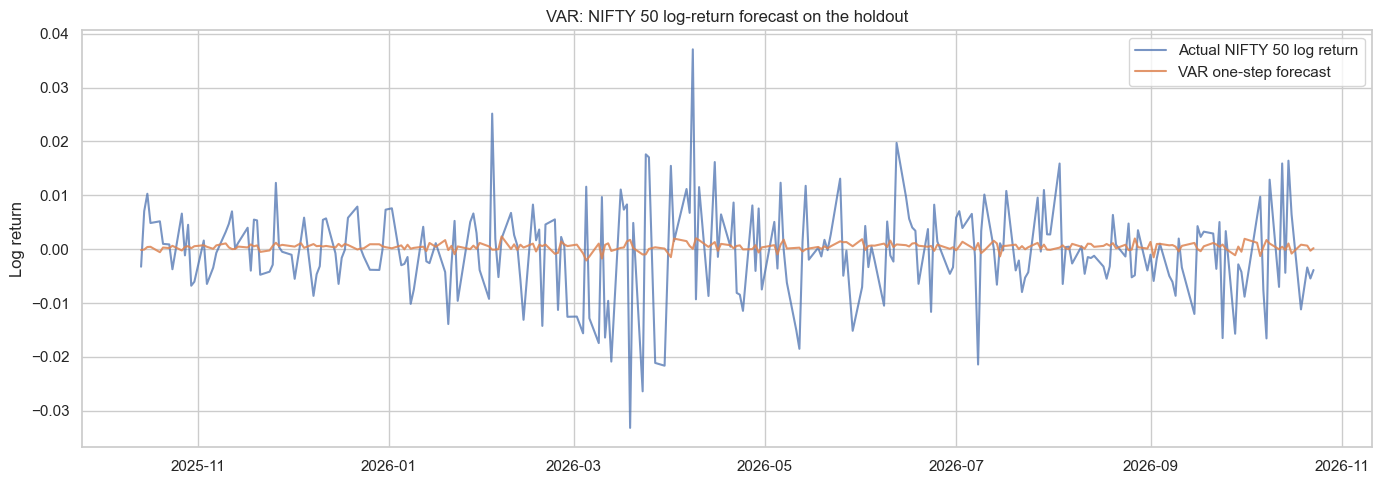

In [27]:
var_columns = ["NIFTY50", "BANK", "IT", "PHARMA", "VIX"]
var_data = returns[var_columns].dropna().copy()
var_split_idx = len(var_data) - TEST_SIZE
var_train = var_data.iloc[:var_split_idx]
var_test = var_data.iloc[var_split_idx:]

# Keep maxlags modest relative to the sample size and number of endogenous series.
maxlags = min(15, max(1, len(var_train) // (10 * len(var_columns))))
var_model = VAR(var_train)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    order_selection = var_model.select_order(maxlags=maxlags)
selected_lag = order_selection.selected_orders.get("aic", 1)
if selected_lag is None or not np.isfinite(selected_lag) or selected_lag < 1:
    selected_lag = 1
selected_lag = int(min(selected_lag, maxlags))
var_result = var_model.fit(selected_lag)
print("Selected VAR lag order:", selected_lag)
print(var_result.summary())

history = var_train.to_numpy().tolist()
var_predictions = []
for actual_row in var_test.to_numpy():
    lag_window = np.asarray(history[-selected_lag:])
    one_step = var_result.forecast(y=lag_window, steps=1)[0]
    var_predictions.append(one_step)
    history.append(actual_row.tolist())

var_pred_df = pd.DataFrame(var_predictions, index=var_test.index, columns=var_test.columns)
var_metrics = []
for col in var_test.columns:
    var_metrics.append({
        "Series": col,
        "MAE (log return)": mean_absolute_error(var_test[col], var_pred_df[col]),
        "RMSE (log return)": np.sqrt(mean_squared_error(var_test[col], var_pred_df[col])),
    })
display(pd.DataFrame(var_metrics).set_index("Series").sort_values("RMSE (log return)"))

plt.figure(figsize=(14, 5))
plt.plot(var_test.index, var_test["NIFTY50"], label="Actual NIFTY 50 log return", alpha=0.75)
plt.plot(var_pred_df.index, var_pred_df["NIFTY50"], label="VAR one-step forecast", alpha=0.85)
plt.title("VAR: NIFTY 50 log-return forecast on the holdout")
plt.ylabel("Log return")
plt.legend()
plt.tight_layout()
plt.show()

## 11. GARCH(1,1): conditional-volatility forecasting

GARCH is applied to NIFTY 50 log returns scaled to percentage units. The model is estimated only on the training returns. Its fitted parameters are then used to generate sequential one-step-ahead volatility forecasts through the holdout, updating the conditional variance after each newly observed return.

Squared returns are a noisy proxy for latent volatility. The QLIKE-style score below is therefore a relative diagnostic, not a direct measurement of the true unobservable volatility.

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                      NIFTY50   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -4724.92
Distribution:      Standardized Student's t   AIC:                           9459.84
Method:                  Maximum Likelihood   BIC:                           9490.77
                                              No. Observations:                 3589
Date:                      Mon, Oct 26 2026   Df Residuals:                     3588
Time:                              23:12:41   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu  

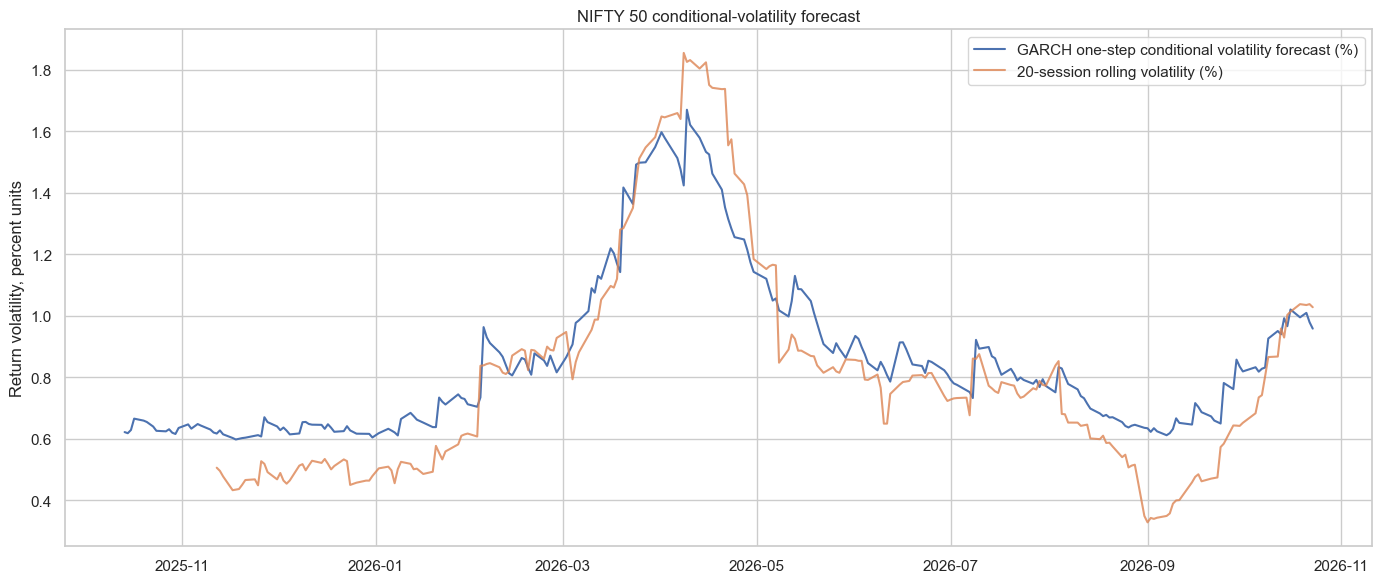

GARCH parameter persistence alpha + beta: 0.9801


In [28]:
if not ARCH_AVAILABLE:
    raise ImportError("Install the arch package with `pip install arch` to run GARCH.")

return_pct = 100 * returns["NIFTY50"]
garch_split = len(return_pct) - TEST_SIZE
garch_train = return_pct.iloc[:garch_split]
garch_test = return_pct.iloc[garch_split:]

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    garch_fit = arch_model(garch_train, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
print(garch_fit.summary())

params = garch_fit.params
omega = float(params["omega"])
alpha1 = float(params["alpha[1]"])
beta1 = float(params["beta[1]"])
mu = float(params.get("mu", 0.0))

variance_prev = float(np.asarray(garch_fit.conditional_volatility)[-1] ** 2)
resid_prev = float(np.asarray(garch_fit.resid)[-1])
garch_vol_forecast = []
for observed_return in garch_test.to_numpy():
    # Forecast today's variance using yesterday's observed residual and conditional variance.
    variance_forecast = max(omega + alpha1 * resid_prev**2 + beta1 * variance_prev, 1e-12)
    garch_vol_forecast.append(np.sqrt(variance_forecast))
    # After observing today's return, carry the state forward for tomorrow's forecast.
    resid_now = float(observed_return - mu)
    variance_prev = variance_forecast
    resid_prev = resid_now

garch_vol_forecast = np.asarray(garch_vol_forecast)
actual_sq_returns = garch_test.to_numpy() ** 2
forecast_var = garch_vol_forecast ** 2
qlike_score = np.mean(np.log(forecast_var) + actual_sq_returns / forecast_var)
print(f"Holdout QLIKE-style score (lower is better for comparable forecasts): {qlike_score:.4f}")

# Compare conditional volatility forecast with a trailing 20-session realized-volatility proxy.
realized_vol_20 = garch_test.rolling(20).std().to_numpy()
plt.figure(figsize=(14, 6))
plt.plot(garch_test.index, garch_vol_forecast, label="GARCH one-step conditional volatility forecast (%)")
plt.plot(garch_test.index, realized_vol_20, label="20-session rolling volatility (%)", alpha=0.8)
plt.title("NIFTY 50 conditional-volatility forecast")
plt.ylabel("Return volatility, percent units")
plt.legend()
plt.tight_layout()
plt.show()

print("GARCH parameter persistence alpha + beta:", round(alpha1 + beta1, 4))

## 12. Anomaly detection in returns

We flag unusually large daily returns using a rolling robust z-score. The median and median absolute deviation (MAD) are estimated from the **previous 60 observations only**, so the current return does not influence its own threshold. A threshold of four is deliberately conservative; this identifies statistical extremes, not necessarily data errors or tradable opportunities.

Detected 30 extreme-return observations at |robust z| >= 4.


,NIFTY50 log return,Return (%),Robust z-score
Date,,,
2020-03-23,-0.139038,-13.903756,-13.605821
2020-03-12,-0.086669,-8.666895,-11.016533
2024-06-04,-0.061124,-6.112420,-10.532661
2020-03-16,-0.079174,-7.917417,-9.554082
2015-08-24,-0.060973,-6.097260,-8.502469
2024-08-05,-0.027152,-2.715175,-6.837308
2020-04-07,0.084003,8.400295,6.391629
2020-03-20,0.056691,5.669139,6.251762
2020-03-18,-0.057168,-5.716793,-6.251730


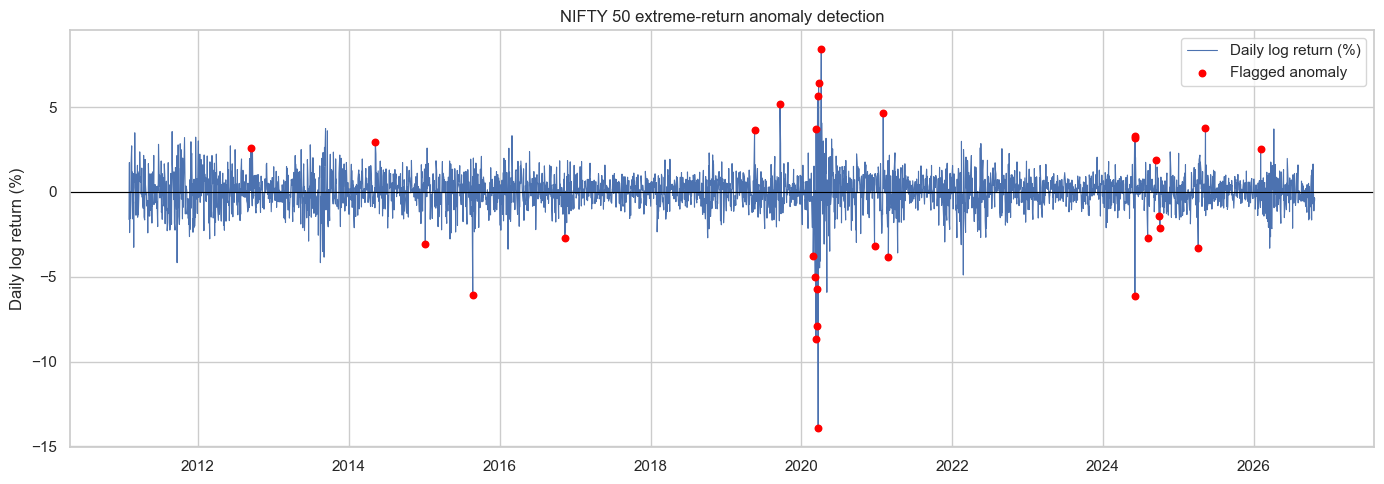

In [29]:
r = returns["NIFTY50"].copy()
ROLLING_WINDOW = 60
rolling_median = r.shift(1).rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).median()
rolling_mad = r.shift(1).rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).apply(
    lambda a: np.median(np.abs(a - np.median(a))), raw=True
)
robust_z = 0.6745 * (r - rolling_median) / rolling_mad.replace(0, np.nan)
anomaly_mask = robust_z.abs() >= 4
anomalies = pd.DataFrame({
    "NIFTY50 log return": r[anomaly_mask],
    "Return (%)": 100 * r[anomaly_mask],
    "Robust z-score": robust_z[anomaly_mask],
}).sort_values("Robust z-score", key=lambda s: s.abs(), ascending=False)

print(f"Detected {len(anomalies)} extreme-return observations at |robust z| >= 4.")
display(anomalies.head(20))

plt.figure(figsize=(14, 5))
plt.plot(r.index, 100 * r, label="Daily log return (%)", linewidth=0.8)
plt.scatter(anomalies.index, anomalies["Return (%)"], color="red", s=22, label="Flagged anomaly", zorder=3)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("NIFTY 50 extreme-return anomaly detection")
plt.ylabel("Daily log return (%)")
plt.legend()
plt.tight_layout()
plt.show()

## 13. Cross-index correlation and volatility clustering

This final diagnostic connects the VAR and GARCH results. Return correlations show how the selected indices move together; the rolling annualized volatility chart highlights periods of calm and stress.

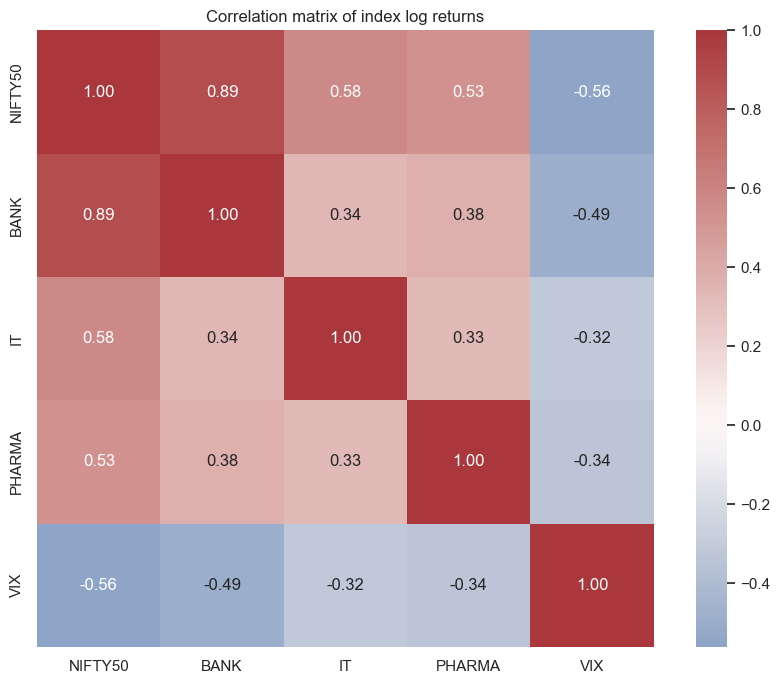

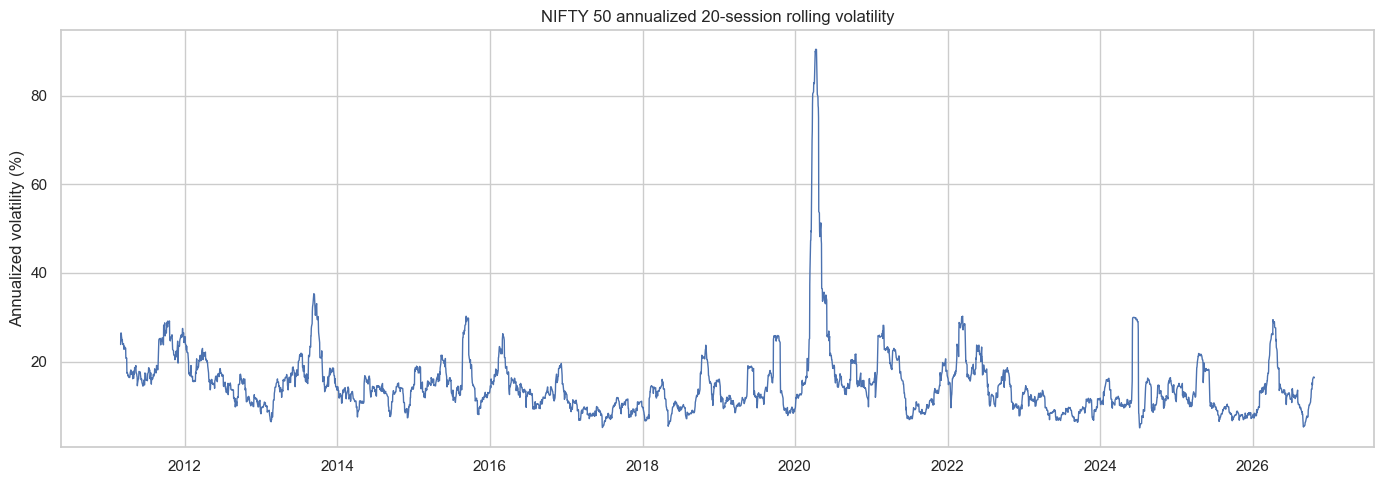

In [30]:
plt.figure(figsize=(9, 7))
sns.heatmap(returns[var_columns].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Correlation matrix of index log returns")
plt.tight_layout()
plt.show()

rolling_vol = returns["NIFTY50"].rolling(20).std() * np.sqrt(252) * 100
plt.figure(figsize=(14, 5))
plt.plot(rolling_vol.index, rolling_vol, linewidth=1.0)
plt.title("NIFTY 50 annualized 20-session rolling volatility")
plt.ylabel("Annualized volatility (%)")
plt.tight_layout()
plt.show()

## 14. Export results and write the findings

The final cells export the main forecast comparison and the detected anomalies. The narrative should be completed only after the notebook has been run and actual outputs checked—do not fill the report with expected or fabricated metrics.

In [31]:
OUTPUT_DIR = "../outputs"
from pathlib import Path
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

forecast_results.to_csv(f"{OUTPUT_DIR}/forecast_model_comparison.csv")
anomalies.to_csv(f"{OUTPUT_DIR}/nifty50_return_anomalies.csv")
var_pred_df.to_csv(f"{OUTPUT_DIR}/var_holdout_predictions.csv")
pd.DataFrame({
    "actual_return_pct": garch_test,
    "garch_forecast_vol_pct": garch_vol_forecast,
    "actual_squared_return_pct2": actual_sq_returns,
}).to_csv(f"{OUTPUT_DIR}/garch_holdout_forecasts.csv")
print(f"Saved tables to ./{OUTPUT_DIR}/")

Saved tables to ./outputs/


## Suggested report structure

1. **Objective:** Forecast NIFTY 50 levels and conditional volatility; analyze relationships across broad-market and sector indices.
2. **Dataset:** Source, fields, effective common date range, row counts and limitations of community-maintained data.
3. **EDA:** Closing levels, rolling averages, monthly-return heatmap, missing-value and coverage checks.
4. **Stationarity and dependence:** ADF/KPSS results, differencing, ACF/PACF for returns and squared returns.
5. **Forecasting:** Naïve baseline, ARIMA, Holt, RNN, LSTM and GRU; compare MAE/RMSE/MAPE and directional accuracy on the same holdout.
6. **Multivariate dynamics:** VAR lag selection, forecast errors and what the fitted coefficients/residual diagnostics suggest.
7. **Volatility:** GARCH parameter estimates, conditional-volatility forecasts and volatility clustering.
8. **Anomalies and decomposition:** Number/date of detected extremes and whether STL reveals stable weekly structure.
9. **Limitations:** Noisy return targets, regime changes, overlapping index constituents, survivorship/measurement limitations, and no transaction costs or trading strategy.
10. **Conclusion:** State which models performed best on the held-out period and whether their gains over the naïve baseline are meaningful.

### Syllabus coverage checklist

| Experiment | Covered in notebook |
|---|---|
| Time-series visualization, heatmap, line plot, rolling mean | Sections 2 and 13 |
| Stationarity testing and differencing | Section 3 |
| ACF/PACF | Section 4 |
| ARIMA modeling and evaluation | Section 7 and forecast comparison |
| STL seasonal decomposition | Section 5 |
| Exponential smoothing | Section 8 |
| VAR | Section 10 |
| GARCH volatility forecasting | Section 11 |
| RNN, LSTM, GRU | Section 9 |
| Anomaly detection | Section 12 |